# AH2179 Traffic project — A5: Neural networks for short-term flow prediction

The A2 MLP used the same *flat* feature table as XGBoost. Traffic data, however, has structure a network can exploit directly:
**time** (the last hour at every portal) and **space** (portals in driving order, congestion waves travel between them).
This notebook feeds the raw 60-minute history of all 8 portals to six network types and compares them with the A2 models.

| Network | Sees the input as | Why it might help |
|---|---|---|
| **MLP (sequence)** | one long vector | baseline network on the same sequence input |
| **LSTM** | a time series of 40 values per step | learns temporal dynamics with memory |
| **GRU** | same | lighter recurrent cell, often as good as LSTM |
| **1D-CNN (dilated, causal)** | a time series | temporal convolutions (TCN-style), fast, captures trends and oscillations |
| **Spatio-temporal CNN** | a 12 × 8 "image" (time × portal) | 2-D filters see patterns that move along the road (waves) |
| **ConvLSTM** | a sequence of 8-portal "rows" | convolution over space inside a recurrent cell — the classic spatio-temporal traffic model |

**Inputs.** Sequence: 12 steps × 8 portals × 5 channels (flow, speed, density, P(congested), missing flag), z-scored with training
statistics, missing values = 0 + flag. Static: time of day, weekday, off-day, historical profile of all portals at the target time,
current flow at 55.620. **Output:** the *change* from the current flow to the flow 15 min ahead (residual learning), /1000.

**Protocol (same as A2):** train on train with early stopping on validation → retrain on all 2021 data (train + val) with the same
number of epochs and learning-rate schedule → score on the ALL-day **evaluation** file. The best network is chosen on **validation**.
The final hold-out is not used (it was already used once for the A2 model).

In [1]:
import warnings, time, json, re; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from scipy import stats
import xgboost as xgb
import traffic_prep as tp
import tensorflow as tf
import tensorflow as tf
try: tf.config.set_visible_devices([], "GPU")   # Mac GPU (tensorflow-metal) gives wrong predictions -> TensorFlow on CPU
except RuntimeError: pass                       # TensorFlow already started in this kernel: restart the kernel
from tensorflow import keras
L = keras.layers

TARGET_P = "p55620"; TARGET = f"q_{TARGET_P}"; Y = f"y_{TARGET}"
assert tp.PORTAL_COL[tp.PORTALS_DOWNSTREAM[7]] == TARGET_P, "sequence code assumes the target is the last (most downstream) portal"
REFIT = False                 # True = retrain everything (ignore cache)
T = 12                        # input window: 12 × 5 min = 60 min
MAX_EPOCHS, PATIENCE, BATCH = 60, 8, 512
N_SEEDS = 3                   # seeds for the best network (seed variation + seed ensemble)
SEED, RES_MIN = 42, 5

IN = Path("../processed_allday"); MOD = Path("../models_allday"); RES = Path("../results_allday"); FIG = Path("../figures_allday")
CACHE = MOD / "cache_A5"; CACHE.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
def save(fig, name): fig.savefig(FIG / f"A5_{name}.png", bbox_inches="tight", dpi=150)
def cached(name, fn):
    f = CACHE / f"{name}.joblib"
    if f.exists() and not REFIT: return joblib.load(f)
    t0 = time.time(); obj = fn(); joblib.dump(obj, f); print(f"[{name}] computed in {time.time() - t0:.0f} s"); return obj

F = {n: pd.read_pickle(IN / f"features_{n}.pkl") for n in ["train", "val", "full", "evaluation"]}   # full = all 2021 (A1)
g = tp.seq_frame(F["train"]); STATS = (g.mean(), g.std().replace(0, 1))    # z-score statistics: train split only
# Sequences are cut from ALL rows of the file: an input value exists whether or not the target is measured 15 min later.
# (Cutting them from the target-filtered table would mark t-5 / t-10 as missing whenever the target at t+10 / t+5 is
#  missing — future information.) The networks are then fitted and scored only where the target exists.
SRC = {"2021": F["full"], "evaluation": F["evaluation"]}
XALL = {k: tp.build_sequences(v, STATS, T) for k, v in SRC.items()}
D = {}
for n in list(F):
    k = "evaluation" if n == "evaluation" else "2021"
    d = F[n] = F[n][F[n][Y].notna()]
    S, _ = tp.nn_static(d, TARGET_P)
    D[n] = {"X": XALL[k][SRC[k].index.get_indexer(d.index)], "S": S, "y": d[Y].to_numpy(np.float32) / 1000 - S[:, 13]}
del XALL
to_flow = lambda out, S: (np.asarray(out).ravel() + S[:, 13]) * 1000.0
print({n: v["X"].shape for n, v in D.items()}, "| static inputs:", D["train"]["S"].shape[1])

{'train': (45401, 12, 8, 5), 'val': (13418, 12, 8, 5), 'full': (58821, 12, 8, 5), 'evaluation': (21824, 12, 8, 5)} | static inputs: 14


## 1. The networks

In [2]:
N_STATIC = D["train"]["S"].shape[1]
BATCH_OF = {"ConvLSTM": 1024}

def head(z, s):
    h = L.Concatenate()([z, s]); h = L.Dense(64, activation="relu")(h); h = L.Dropout(0.2)(h)
    return L.Dense(1)(h)

def build(kind):
    xs = keras.Input((T, 8, 5), name="sequence"); st = keras.Input((N_STATIC,), name="static")
    flat_t = L.Reshape((T, 40))(xs)                       # [time, portals × channels]
    if kind == "MLP (sequence)":
        z = L.Dropout(0.2)(L.Dense(256, activation="relu")(L.Flatten()(xs)))
    elif kind == "LSTM":
        z = L.LSTM(64)(flat_t)
    elif kind == "GRU":
        z = L.GRU(64)(flat_t)
    elif kind == "1D-CNN":
        h = flat_t
        for d in (1, 2, 4):                                 # receptive field 15 steps ≥ window
            h = L.Conv1D(64, 3, padding="causal", dilation_rate=d, activation="relu")(h)
        z = L.Flatten()(h)
    elif kind == "Spatio-temporal CNN":
        h = L.Conv2D(32, (3, 3), padding="same", activation="relu")(xs)
        h = L.Conv2D(32, (3, 3), padding="same", activation="relu")(h)
        z = L.Flatten()(h)
    elif kind == "ConvLSTM":
        z = L.Flatten()(L.ConvLSTM1D(24, 3, padding="same")(xs))
    m = keras.Model([xs, st], head(z, st), name="net_" + re.sub(r"\W", "_", kind))
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return m

KINDS = ["MLP (sequence)", "LSTM", "GRU", "1D-CNN", "Spatio-temporal CNN", "ConvLSTM"]
pd.Series({k: build(k).count_params() for k in KINDS}, name="trainable parameters").to_frame()

,trainable parameters
MLP (sequence),140545
LSTM,32001
GRU,25473
1D-CNN,82625
Spatio-temporal CNN,208353
ConvLSTM,21761


## 2. Training: train → early stopping on validation → retrain on all 2021 data
The retraining reuses the number of epochs (×1.15 for the larger data set) and the learning-rate schedule of the first run,
because there is no validation set left to steer it.

In [3]:
def fit_train(kind, seed=SEED):
    keras.utils.set_random_seed(seed); m = build(kind); lrs = []
    rec = keras.callbacks.LambdaCallback(on_epoch_end=lambda e, logs: lrs.append(float(keras.ops.convert_to_numpy(m.optimizer.learning_rate))))
    t0 = time.time()
    h = m.fit([D["train"]["X"], D["train"]["S"]], D["train"]["y"],
              validation_data=([D["val"]["X"], D["val"]["S"]], D["val"]["y"]),
              epochs=MAX_EPOCHS, batch_size=BATCH_OF.get(kind, BATCH), verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True),
                         keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3), rec])
    return {"hist": {k: list(map(float, v)) for k, v in h.history.items()}, "lrs": lrs,
            "best_epoch": int(np.argmin(h.history["val_loss"])) + 1, "seconds": time.time() - t0,
            "val": to_flow(m.predict([D["val"]["X"], D["val"]["S"]], verbose=0, batch_size=4096), D["val"]["S"])}

def fit_full(kind, info, X, S, y, seed=SEED, save_as=None):
    keras.utils.set_random_seed(seed); m = build(kind)
    n_ep = int(np.ceil(info["best_epoch"] * 1.15)); lrs = info["lrs"]
    sched = keras.callbacks.LearningRateScheduler(lambda e, lr: lrs[min(int(e / 1.15), len(lrs) - 1)])
    m.fit([X, S], y, epochs=n_ep, batch_size=BATCH_OF.get(kind, BATCH), verbose=0, callbacks=[sched])
    if save_as: m.save(MOD / save_as)
    return {"evaluation": to_flow(m.predict([D["evaluation"]["X"], D["evaluation"]["S"]], verbose=0, batch_size=4096), D["evaluation"]["S"])}

fname = lambda k: k.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("-", "")
INFO, EVAL = {}, {}
for k in KINDS:
    INFO[k] = cached(f"train_{fname(k)}", lambda k=k: fit_train(k))
    EVAL[k] = cached(f"full_{fname(k)}", lambda k=k: fit_full(k, INFO[k], D["full"]["X"], D["full"]["S"], D["full"]["y"],
                                                               save_as=f"nn_{fname(k)}_{TARGET}.keras"))
pd.DataFrame({k: {"parameters": build(k).count_params(), "best epoch": INFO[k]["best_epoch"],
                  "training time (s)": round(INFO[k]["seconds"])} for k in KINDS}).T

,parameters,best epoch,training time (s)
MLP (sequence),140545,17,10
LSTM,32001,28,68
GRU,25473,15,45
1D-CNN,82625,12,25
Spatio-temporal CNN,208353,8,36
ConvLSTM,21761,20,116


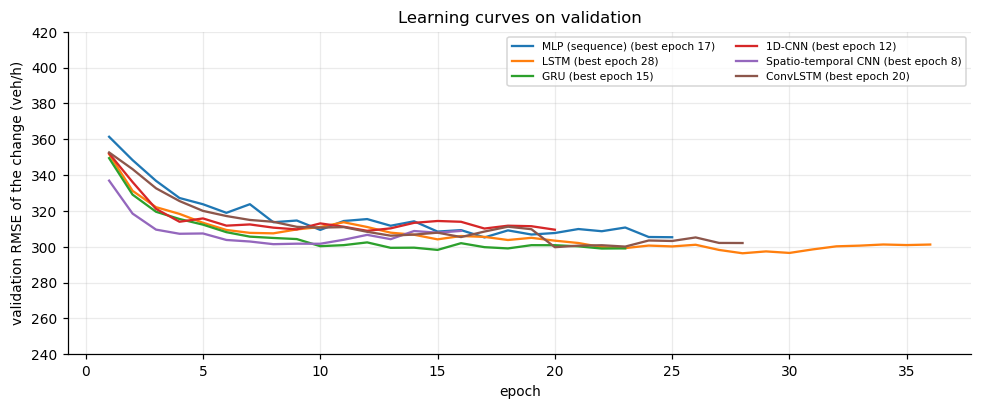

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, k in enumerate(KINDS):
    v = np.sqrt(INFO[k]["hist"]["val_loss"]) * 1000
    ax.plot(range(1, len(v) + 1), v, color=f"C{i}", lw=1.5, label=f"{k} (best epoch {INFO[k]['best_epoch']})")
ax.set(xlabel="epoch", ylabel="validation RMSE of the change (veh/h)", title="Learning curves on validation", ylim=(240, 420))
ax.legend(fontsize=7, ncol=2); fig.tight_layout(); save(fig, "learning_curves"); plt.show()

## 3. Results

In [5]:
def subsets(d):
    ok = d[Y].notna(); tod = d["tod_target_min"]; rt = d[f"r_{TARGET_P}_lag0"]; ry = d[f"y_reg_{TARGET}"]
    return {"all day": ok, "07:30–08:30": ok & tod.between(450, 510), "15:00–18:00": ok & tod.between(900, 1080),
            "free flow at t+15": ok & (ry == 0), "congested at t+15": ok & (ry == 1),
            "onset (free→cong)": ok & (rt < .5) & (ry == 1), "recovery (cong→free)": ok & (rt >= .5) & (ry == 0)}

def rmse_table(preds, split):
    d = F[split]; y = d[Y]; S_ = subsets(d)
    P_ = {k: pd.Series(np.asarray(p), index=d.index) if not isinstance(p, pd.Series) else p.reindex(d.index) for k, p in preds.items()}
    t = pd.DataFrame({s: {k: np.sqrt(((p[m] - y[m]) ** 2).mean()) for k, p in P_.items()} for s, m in S_.items()}).T
    t.insert(0, "n", [int(m.sum()) for m in S_.values()]); return t.round(0)

# references from A2
prep = joblib.load(MOD / f"prep_{TARGET}.joblib"); X_BASE = prep["x_cols"]
a2 = pd.read_pickle(RES / f"predictions_evaluation_{TARGET}.pkl").reindex(F["evaluation"].index)
ref_eval = {"persistence": a2["persistence"], "A2 MLP (flat features)": a2["mlp"], "A2 XGBoost + aug (selected)": a2["xgb single + aug"]}
ref_val = {"persistence": F["val"][f"{TARGET}_lag0"].fillna(F["val"][f"hist_{TARGET}"])}
try:                                                     # XGBoost trained on train only (A2 cache), for a fair validation reference
    xtr = joblib.load(MOD / "cache" / "xgb_single_train.joblib")
    ref_val["A2 XGBoost (train only)"] = pd.Series(xtr.predict(F["val"][X_BASE], iteration_range=(0, xtr.best_iteration + 1)), index=F["val"].index)
except Exception as e:
    print("validation reference for XGBoost not available:", e)

val_tab = rmse_table({**ref_val, **{k: INFO[k]["val"] for k in KINDS}}, "val")
BEST_NN = val_tab.loc["all day", KINDS].idxmin()
print("best network on VALIDATION:", BEST_NN)
val_tab.to_csv(RES / f"A5_val_rmse_{TARGET}.csv"); val_tab

best network on VALIDATION: LSTM


,n,persistence,A2 XGBoost (train only),MLP (sequence),LSTM,GRU,1D-CNN,Spatio-temporal CNN,ConvLSTM
all day,13418,382.0,284.0,305.0,296.0,298.0,309.0,301.0,300.0
07:30–08:30,611,355.0,272.0,337.0,328.0,323.0,351.0,330.0,326.0
15:00–18:00,1738,558.0,458.0,461.0,458.0,461.0,466.0,464.0,464.0
free flow at t+15,11992,347.0,243.0,269.0,260.0,262.0,274.0,265.0,264.0
congested at t+15,1426,604.0,512.0,519.0,506.0,510.0,516.0,516.0,509.0
onset (free→cong),156,716.0,597.0,605.0,586.0,603.0,622.0,605.0,619.0
recovery (cong→free),168,1077.0,617.0,650.0,628.0,602.0,645.0,606.0,600.0


In [6]:
ev_pred = {**ref_eval, **{k: EVAL[k]["evaluation"] for k in KINDS}}
ev_tab = rmse_table(ev_pred, "evaluation"); ev_tab.to_csv(RES / f"A5_evaluation_rmse_{TARGET}.csv")
ev_tab

,n,persistence,A2 MLP (flat features),A2 XGBoost + aug (selected),MLP (sequence),LSTM,GRU,1D-CNN,Spatio-temporal CNN,ConvLSTM
all day,21824,403.0,337.0,300.0,323.0,319.0,318.0,325.0,336.0,310.0
07:30–08:30,1040,411.0,322.0,268.0,301.0,311.0,313.0,297.0,313.0,314.0
15:00–18:00,2958,559.0,494.0,464.0,491.0,477.0,481.0,491.0,551.0,476.0
free flow at t+15,19646,370.0,304.0,259.0,286.0,280.0,281.0,287.0,288.0,271.0
congested at t+15,2177,623.0,548.0,544.0,553.0,557.0,549.0,564.0,620.0,549.0
onset (free→cong),297,749.0,665.0,663.0,635.0,667.0,645.0,654.0,673.0,658.0
recovery (cong→free),289,1045.0,676.0,552.0,645.0,610.0,573.0,600.0,688.0,634.0


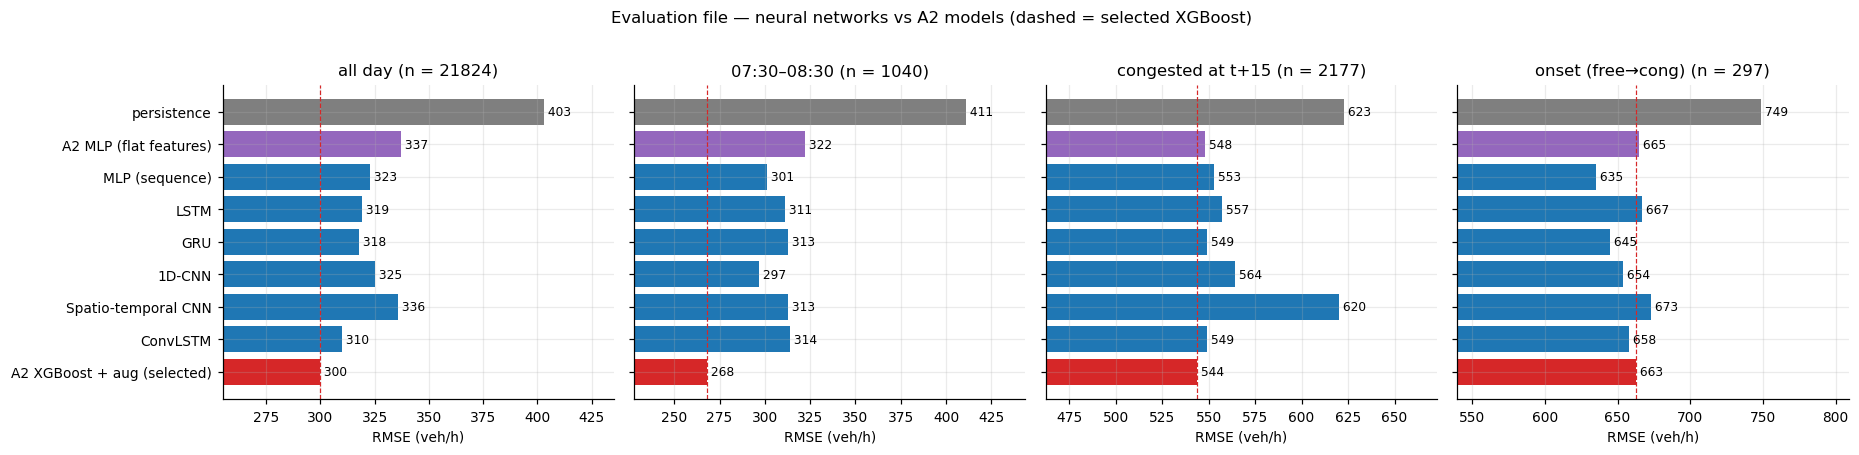

In [7]:
order = ["persistence", "A2 MLP (flat features)"] + KINDS + ["A2 XGBoost + aug (selected)"]
colors = ["C7", "C4"] + ["C0"] * len(KINDS) + ["C3"]
subs = ["all day", "07:30–08:30", "congested at t+15", "onset (free→cong)"]
fig, ax = plt.subplots(1, len(subs), figsize=(17, 4), sharey=True)
for a, s in zip(ax, subs):
    v = ev_tab.loc[s, order]
    a.barh(range(len(order)), v, color=colors)
    for i, x in enumerate(v): a.text(x, i, f" {x:.0f}", va="center", fontsize=8)
    a.axvline(ev_tab.loc[s, "A2 XGBoost + aug (selected)"], color="C3", ls="--", lw=.8)
    a.set_xlim(v.min() * .85, v.max() * 1.08); a.set(title=f"{s} (n = {int(ev_tab.loc[s, 'n'])})", xlabel="RMSE (veh/h)")
ax[0].set_yticks(range(len(order)), order); ax[0].invert_yaxis()
fig.suptitle("Evaluation file — neural networks vs A2 models (dashed = selected XGBoost)", y=1.02)
fig.tight_layout(); save(fig, "rmse_by_subset"); plt.show()

## 4. Are the differences real? Day-level paired tests
Same method as A3/A4: paired t-test on daily mean squared-error differences (days are ~independent, 5-min rows are not),
effect size ΔRMSE with a day-block bootstrap 95 % CI, Holm correction over all comparisons in the table.

In [8]:
def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(o): run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def day_test(pa, pb, split, sub):
    d = F[split]; m = subsets(d)[sub]; y = d[Y][m]
    pa, pb = pd.Series(np.asarray(pa), index=d.index)[m], pd.Series(np.asarray(pb), index=d.index)[m]
    day = (d.index[m] - pd.Timedelta(minutes=RES_MIN)).normalize()
    Lg = pd.DataFrame({"a": (pa - y) ** 2, "b": (pb - y) ** 2}).groupby(day)
    S_, n = Lg.sum().to_numpy(), Lg.size().to_numpy(); dd = (S_[:, 0] - S_[:, 1]) / n
    t = stats.ttest_1samp(dd, 0)
    idx = np.random.default_rng(SEED).integers(0, len(n), (2000, len(n)))
    r = np.sqrt(S_[idx].sum(1) / n[idx].sum(1)[:, None]); lo, hi = np.percentile(r[:, 0] - r[:, 1], [2.5, 97.5])
    return {"ΔRMSE": np.sqrt(S_[:, 0].sum() / n.sum()) - np.sqrt(S_[:, 1].sum() / n.sum()), "lo": lo, "hi": hi, "days": len(n), "p": t.pvalue}

rows = []
for k in KINDS:
    for ref in ["A2 XGBoost + aug (selected)", "A2 MLP (flat features)"]:
        for s in ["all day", "07:30–08:30", "congested at t+15"]:
            rows.append({"network": k, "vs": ref, "subset": s, **day_test(ev_pred[k], ev_pred[ref], "evaluation", s)})
TESTS = pd.DataFrame(rows); TESTS["p (Holm)"] = holm(TESTS["p"])
TESTS.to_csv(RES / f"A5_tests_{TARGET}.csv", index=False)
show = TESTS.assign(**{"95% CI": lambda t: "[" + t.lo.round(1).astype(str) + ", " + t.hi.round(1).astype(str) + "]"})
show["ΔRMSE"] = show["ΔRMSE"].round(1); show["p (Holm)"] = show["p (Holm)"].map("{:.2g}".format); show["p"] = show["p"].map("{:.2g}".format)
show.pivot(index="network", columns=["vs", "subset"], values="ΔRMSE").astype(str) + np.where(
    TESTS.pivot(index="network", columns=["vs", "subset"], values="p (Holm)") < .05, " *", "")

vs                  A2 XGBoost + aug (selected)                                \
subset                                  all day 07:30–08:30 congested at t+15   
network                                                                         
1D-CNN                                   25.4 *      29.8 *              19.8   
ConvLSTM                                 10.3 *      46.9 *               4.5   
GRU                                      17.8 *      45.5 *               4.8   
LSTM                                     19.1 *        43.8              13.1   
MLP (sequence)                           23.0 *      33.8 *               8.6   
Spatio-temporal CNN                      36.4 *      45.0 *              75.4   

vs                  A2 MLP (flat features)                                
subset                             all day 07:30–08:30 congested at t+15  
network                                                                   
1D-CNN                               -11.2       -24.8              15.5  
ConvLSTM                           -26.3 *        -7.7               0.2  
GRU                                -18.8 *        -9.1               0.5  
LSTM                               -17.6 *       -10.8               8.8  
MLP (sequence)                     -13.6 *       -20.8               4.3  
Spatio-temporal CNN                   -0.3        -9.6            71.1 *

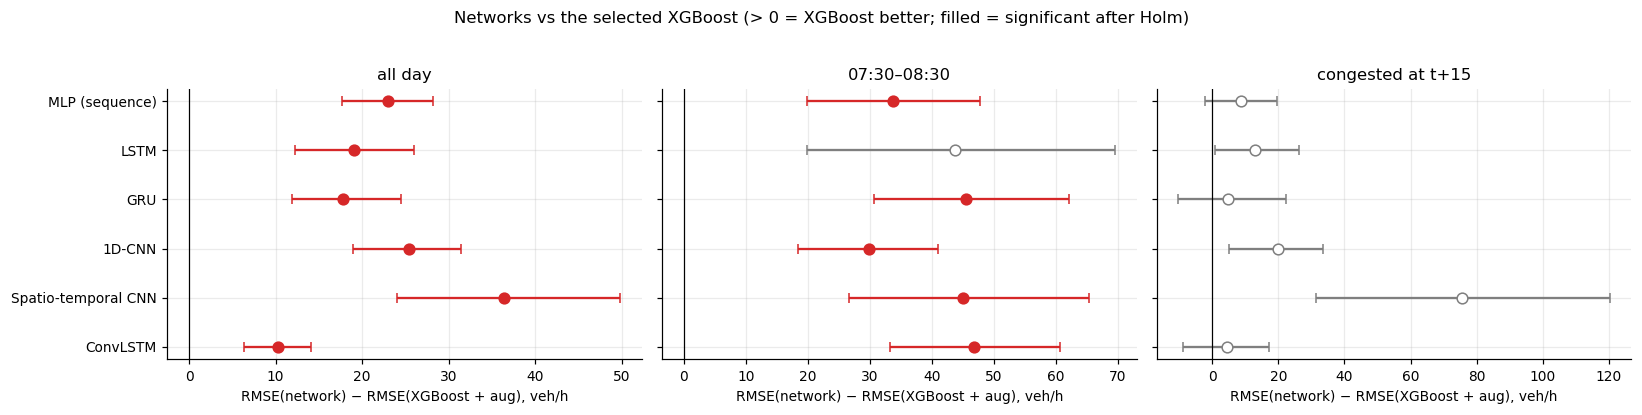

In [9]:
t_ = TESTS[TESTS.vs == "A2 XGBoost + aug (selected)"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for a, s in zip(ax, ["all day", "07:30–08:30", "congested at t+15"]):
    tt = t_[t_.subset == s].set_index("network").loc[KINDS]
    for i, (k, r) in enumerate(tt.iterrows()):
        sig = r["p (Holm)"] < .05
        a.errorbar(r["ΔRMSE"], i, xerr=[[r["ΔRMSE"] - r["lo"]], [r["hi"] - r["ΔRMSE"]]], fmt="o", capsize=3,
                   color="C3" if sig else "C7", mfc="C3" if sig else "white", ms=7)
    a.axvline(0, color="k", lw=.8); a.set(title=s, xlabel="RMSE(network) − RMSE(XGBoost + aug), veh/h")
ax[0].set_yticks(range(len(KINDS)), KINDS); ax[0].invert_yaxis()
fig.suptitle("Networks vs the selected XGBoost (> 0 = XGBoost better; filled = significant after Holm)", y=1.03)
fig.tight_layout(); save(fig, "tests_vs_xgboost"); plt.show()

## 5. The best network: seed variation, seed ensemble and an XGBoost + network ensemble
Networks depend on the random initialisation. The network chosen on validation is retrained with 3 seeds; the spread shows how much
of a difference between networks is just luck, and averaging the seeds (a *seed ensemble*) usually helps. Finally the seed ensemble
is averaged 50/50 with the selected XGBoost — trees and networks make different errors, so a simple average can beat both.

In [10]:
SEEDS = [SEED + i for i in range(N_SEEDS)]
seed_pred = {sd: (EVAL[BEST_NN]["evaluation"] if sd == SEED else
                  cached(f"full_{fname(BEST_NN)}_seed{sd}", lambda sd=sd: fit_full(BEST_NN, INFO[BEST_NN], D["full"]["X"], D["full"]["S"], D["full"]["y"], seed=sd))["evaluation"])
             for sd in SEEDS}
yv = F["evaluation"][Y].to_numpy()
per_seed = pd.Series({sd: np.sqrt(((p - yv) ** 2).mean()) for sd, p in seed_pred.items()})
print(f"{BEST_NN}: all-day RMSE per seed {per_seed.round(1).to_dict()} → mean {per_seed.mean():.1f} ± {per_seed.std():.1f} veh/h")
ens_nn = np.mean(list(seed_pred.values()), axis=0)
ev_pred[f"{BEST_NN} — {N_SEEDS}-seed ensemble"] = ens_nn
ev_pred[f"XGBoost + aug ⊕ {BEST_NN} ensemble (50/50)"] = 0.5 * ev_pred["A2 XGBoost + aug (selected)"].to_numpy() + 0.5 * ens_nn
keys = ["persistence", "A2 XGBoost + aug (selected)", BEST_NN, f"{BEST_NN} — {N_SEEDS}-seed ensemble", f"XGBoost + aug ⊕ {BEST_NN} ensemble (50/50)"]
ens_tab = rmse_table({k: ev_pred[k] for k in keys}, "evaluation"); ens_tab.to_csv(RES / f"A5_ensembles_{TARGET}.csv")
rows = [{"model": k, "subset": s, **day_test(ev_pred[k], ev_pred["A2 XGBoost + aug (selected)"], "evaluation", s)}
        for k in keys[2:] for s in ["all day", "07:30–08:30", "congested at t+15", "onset (free→cong)"]]
ENS = pd.DataFrame(rows); ENS["p (Holm)"] = holm(ENS["p"]); ENS.to_csv(RES / f"A5_ensemble_tests_{TARGET}.csv", index=False)
display(ens_tab)
ENS.round({"ΔRMSE": 1, "lo": 1, "hi": 1}).assign(p=lambda t: t.p.map("{:.2g}".format), **{"p (Holm)": lambda t: t["p (Holm)"].map("{:.2g}".format)})

LSTM: all-day RMSE per seed {42: 319.0, 43: 314.5, 44: 322.4} → mean 318.7 ± 4.0 veh/h


,n,persistence,A2 XGBoost + aug (selected),LSTM,LSTM — 3-seed ensemble,XGBoost + aug ⊕ LSTM ensemble (50/50)
all day,21824,403.0,300.0,319.0,310.0,298.0
07:30–08:30,1040,411.0,268.0,311.0,289.0,272.0
15:00–18:00,2958,559.0,464.0,477.0,471.0,460.0
free flow at t+15,19646,370.0,259.0,280.0,268.0,257.0
congested at t+15,2177,623.0,544.0,557.0,561.0,543.0
onset (free→cong),297,749.0,663.0,667.0,661.0,657.0
recovery (cong→free),289,1045.0,552.0,610.0,582.0,557.0


,model,subset,ΔRMSE,lo,hi,days,p,p (Holm)
0,LSTM,all day,19.1,12.3,26.0,80,1.3e-06,1.5e-05
1,LSTM,07:30–08:30,43.8,19.9,69.6,80,0.0038,0.038
2,LSTM,congested at t+15,13.1,0.7,26.4,60,0.028,0.2
3,LSTM,onset (free→cong),4.0,-23.8,32.9,60,0.97,1
4,LSTM — 3-seed ensemble,all day,10.1,5.9,14.6,80,2.2e-05,0.00025
5,LSTM — 3-seed ensemble,07:30–08:30,21.4,8.1,33.5,80,0.0095,0.085
6,LSTM — 3-seed ensemble,congested at t+15,16.4,1.4,32.8,60,0.032,0.2
7,LSTM — 3-seed ensemble,onset (free→cong),-2.5,-27.3,22.6,60,0.91,1
8,XGBoost + aug ⊕ LSTM ensemble (50/50),all day,-2.0,-3.7,-0.3,80,0.025,0.2
9,XGBoost + aug ⊕ LSTM ensemble (50/50),07:30–08:30,4.3,-3.0,10.9,80,0.26,1


## 6. Robustness: the best network with masking augmentation
Same idea as A2: two extra copies of the training data with random portals / values blanked (flag = 1, value = 0). If the target
portal itself is blanked, the "current flow" input falls back to the historical profile. Compared with the selected XGBoost under
the same failure scenarios (the XGBoost is masked on its own feature table; the random 20 % masks are drawn separately for the two
input formats).

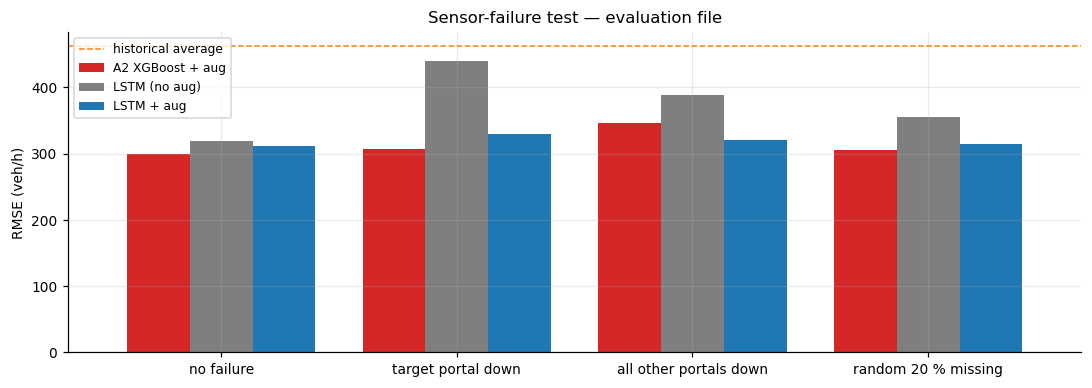

,A2 XGBoost + aug,LSTM (no aug),LSTM + aug
no failure,300.0,319.0,311.0
target portal down,307.0,440.0,330.0
all other portals down,347.0,388.0,320.0
random 20 % missing,305.0,356.0,314.0


In [11]:
def fit_aug():
    Xa, Sa = tp.augment_sequences(D["full"]["X"], D["full"]["S"], n_copies=2, seed=1)
    ya = np.tile(F["full"][Y].to_numpy(np.float32) / 1000, 3) - Sa[:, 13]
    return fit_full(BEST_NN, INFO[BEST_NN], Xa, Sa, ya, save_as=f"nn_best_aug_{TARGET}.keras")
aug_ev = cached(f"full_aug_{fname(BEST_NN)}", fit_aug)
ev_pred[f"{BEST_NN} + aug"] = aug_ev["evaluation"]
nn_plain = keras.models.load_model(MOD / f"nn_{fname(BEST_NN)}_{TARGET}.keras")
nn_aug = keras.models.load_model(MOD / f"nn_best_aug_{TARGET}.keras")
Xe, Se = D["evaluation"]["X"], D["evaluation"]["S"]
NN_SCEN = {"no failure": (None, 0.0), "target portal down": ([7], 0.0), "all other portals down": (list(range(7)), 0.0), "random 20 % missing": (None, 0.2)}
a2m = xgb.XGBRegressor(); a2m.load_model(MOD / f"xgb_single_aug_{TARGET}.json")
pf = tp.portal_feature_map(X_BASE); own = pf[TARGET_P]
others = sorted({c for p_, cs in pf.items() if p_ != TARGET_P for c in cs} - set(own)); vcols = sorted({c for cs in pf.values() for c in cs})
def xgb_scen(name, d):
    d = d.copy()
    if name == "target portal down": d[own] = np.nan
    if name == "all other portals down": d[others] = np.nan
    if name == "random 20 % missing": d[vcols] = d[vcols].mask(np.random.default_rng(SEED).random((len(d), len(vcols))) < .2)
    return a2m.predict(d[X_BASE])
rob = {}
for name, (ports, frac) in NN_SCEN.items():
    Xm, Sm = tp.mask_sequences(Xe, Se, ports, frac, seed=SEED)
    r = lambda p: np.sqrt(((np.asarray(p) - yv) ** 2).mean())
    rob[name] = {"A2 XGBoost + aug": r(xgb_scen(name, F["evaluation"])),
                 f"{BEST_NN} (no aug)": r(to_flow(nn_plain.predict([Xm, Sm], verbose=0, batch_size=4096), Sm)),
                 f"{BEST_NN} + aug": r(to_flow(nn_aug.predict([Xm, Sm], verbose=0, batch_size=4096), Sm))}
ROB = pd.DataFrame(rob).T.round(0); ROB.to_csv(RES / f"A5_robustness_{TARGET}.csv")
fig, ax = plt.subplots(figsize=(10, 3.6)); ROB.plot.bar(ax=ax, rot=0, color=["C3", "C7", "C0"], width=.8)
ax.axhline(rmse_table({"h": F["evaluation"][f"hist_{TARGET}"]}, "evaluation").loc["all day", "h"], color="C1", ls="--", lw=1, label="historical average")
ax.set(ylabel="RMSE (veh/h)", title="Sensor-failure test — evaluation file"); ax.legend(fontsize=8)
ax.set_ylim(0, min(ROB.to_numpy().max() * 1.1, 1200)); fig.tight_layout(); save(fig, "robustness"); plt.show()
ROB

## 7. Where do networks and XGBoost differ?

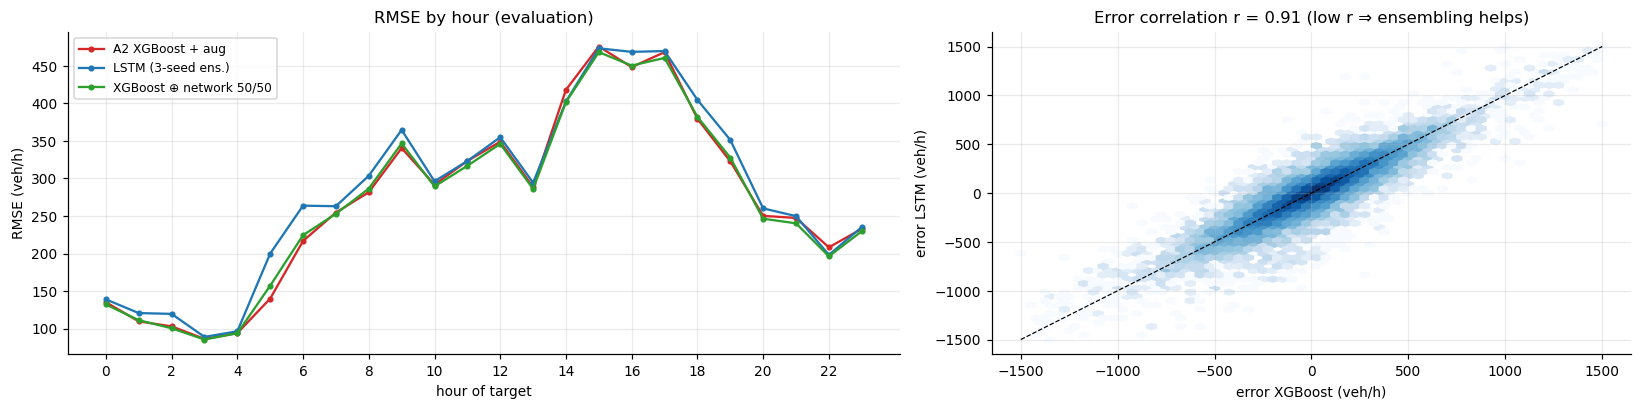

In [12]:
d = F["evaluation"]; hour = d["tod_target_min"] // 60
comp = {"A2 XGBoost + aug": ev_pred["A2 XGBoost + aug (selected)"].to_numpy(), f"{BEST_NN} ({N_SEEDS}-seed ens.)": ens_nn,
        "XGBoost ⊕ network 50/50": ev_pred[f"XGBoost + aug ⊕ {BEST_NN} ensemble (50/50)"]}
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
for (k, p), c in zip(comp.items(), ["C3", "C0", "C2"]):
    ax[0].plot(pd.Series((p - yv) ** 2, index=d.index).groupby(hour).mean() ** .5, "o-", ms=3, color=c, label=k)
ax[0].set(xlabel="hour of target", ylabel="RMSE (veh/h)", title="RMSE by hour (evaluation)"); ax[0].legend(fontsize=8); ax[0].set_xticks(range(0, 24, 2))
e1, e2 = comp["A2 XGBoost + aug"] - yv, ens_nn - yv
ax[1].hexbin(e1, e2, gridsize=60, bins="log", cmap="Blues", mincnt=1, extent=(-1500, 1500, -1500, 1500))
ax[1].plot([-1500, 1500], [-1500, 1500], "k--", lw=.8)
ax[1].set(xlabel="error XGBoost (veh/h)", ylabel=f"error {BEST_NN} (veh/h)", title=f"Error correlation r = {np.corrcoef(e1, e2)[0, 1]:.2f} (low r ⇒ ensembling helps)")
fig.tight_layout(); save(fig, "xgb_vs_nn"); plt.show()

In [13]:
json.dump({"best_network": BEST_NN, "files": {"plain": f"nn_{fname(BEST_NN)}_{TARGET}.keras", "augmented": f"nn_best_aug_{TARGET}.keras"},
           "window_steps": T, "channels": ["flow", "speed", "density", "P(congested)", "missing flag"],
           "portals_in_order": [tp.PORTAL_COL[k] for k in tp.PORTALS_DOWNSTREAM],
           "zscore_mean": STATS[0].round(6).to_dict(), "zscore_std": STATS[1].round(6).to_dict(),
           "static_inputs": ["sin tod", "cos tod", "dow_sin", "dow_cos", "is_offday"] + [f"hist_q_{tp.PORTAL_COL[k]}/1000" for k in tp.PORTALS_DOWNSTREAM] + ["current flow/1000"],
           "output": "(flow at t+15 − current flow) / 1000"}, open(MOD / f"nn_config_{TARGET}.json", "w"), indent=1)
print("saved", MOD / f"nn_{fname(BEST_NN)}_{TARGET}.keras", "and", MOD / f"nn_best_aug_{TARGET}.keras")

saved ../models_allday/nn_lstm_q_p55620.keras and ../models_allday/nn_best_aug_q_p55620.keras


## Interpretation (leakage-safe rerun — check against your own numbers)

**Sequence input helps most networks.** ConvLSTM, GRU, LSTM and the sequence MLP beat the A2 MLP on flat features by 14–26 veh/h
all day (significant after Holm); the 1D-CNN by 11 veh/h (not significant after Holm); the spatio-temporal CNN not at all in this
run (336 veh/h, weak in the afternoon peak).

**…but XGBoost is still better.** All six networks are 10–36 veh/h worse than the selected XGBoost all day and 30–47 veh/h worse on
the 07:30–08:30 window (significant after Holm for all but the LSTM); in congestion the gap is 4–20 veh/h and not significant after
Holm; the spatio-temporal CNN is 75 veh/h worse there. Best on the evaluation file: ConvLSTM 310 veh/h; chosen on validation: LSTM (296 on
validation, 319 on evaluation; 3 seeds: 318.7 ± 4.0 — differences of a few veh/h between networks are within seed noise).

**Ensembles do not help much.** Averaging 3 LSTM seeds gains 9 veh/h (310); averaging the LSTM with XGBoost gives 298 vs 300 veh/h
(−2.0, CI −3.7…−0.3, not significant after Holm) — both models miss the *same* events (the congestion waves from the downstream
bottleneck, see A4).

**Why trees win on this problem:** ~60 000 training rows is small for deep learning; XGBoost gets strong hand-made features
(historical profile, regime, density) and handles missing data natively; and the remaining error is dominated by information that
is not in the inputs (A4 noise-floor analysis), so a more flexible model cannot extract more.

**Robustness:** without augmentation the LSTM degrades to 356–440 veh/h under sensor failures; with masking augmentation it stays at
311–330 veh/h, close to XGBoost + aug (300–347) and better than it when all other portals are down (320 vs 347).

**For the report / deliverables:** keep XGBoost + aug (A2) as the selected model. For the required `.keras` file the LSTM + aug
(`nn_best_aug_q_p55620.keras`, 311 veh/h, robust to failures) is a better Keras model than the A2 MLP (337 veh/h) — it was chosen on
validation. The results here are on the evaluation file; the final hold-out was not used.

*Leakage fix: besides the A1 changes, the sequences are now cut from all rows of the file instead of the target-filtered table.
Before, a missing target at t+5 / t+10 marked the inputs at t−10 / t−5 as missing — information from the future.*